(course-alzheimer-comparison-superposition)=

# Path A - Module 34: Comparison & Superposition

How much does your model change during simulation? To answer this, you cannot just look at coordinates, because the whole system might have rotated or translated in the box. You need to **Align** the structures first.

In this module, you will learn to calculate structural similarity using the **RMSD** (Root Mean Square Deviation) and perform spatial superpositions.

`least_rmsd_align()` returns an aligned molecular system. Use `get_rmsd()`
with the corresponding anchor selections to measure its residual RMSD. Its
selections always address atoms; the sequence provider independently maps their
amino-acid groups. Complete components containing the query anchors move.
See {ref}`Tutorial_Least_rmsd_align` and
{ref}`Cookbook_Aligning_Components_By_Sequence` for ownership and scope details.


(course-alzheimer-comparison-superposition-inputs)=
### 1. Preparing a comparison

You use a small bundled Villin ensemble as a reproducible structural
comparison example. The selected atom and structure axes stay explicit. The
reference is original structure 1; structures are requested in nonconsecutive
order, including a repeated index. A genuine conformational difference need
not have zero RMSD after fitting.


In [1]:
import molsysmt as msm
from molsysmt import systems

villin_traj = systems['chicken villin HP35']['traj_chicken_villin_HP35_solvated.dcd']
villin_topo = systems['chicken villin HP35']['chicken_villin_HP35_solvated.h5msm']
# HP35 is classified as a peptide. Select either biological chain type.
topology = msm.convert(villin_topo, to_form='molsysmt.Topology')
molsys = msm.convert([topology, villin_traj], to_form='molsysmt.MolSys',
    selection='molecule_type=="protein" or molecule_type=="peptide"',
    structure_indices=[0, 8, 3])

import numpy as np
import matplotlib.pyplot as plt
puw = msm.pyunitwizard

atoms = msm.select(molsys, selection='atom_name=="CA"')
requested = [2, 0, 2]


(course-alzheimer-comparison-superposition-raw)=
### 2. Measuring the original difference

Measure raw RMSD over the atoms you will use as fit anchors.


In [2]:
rmsd_raw = msm.structure.get_rmsd(
    molsys, selection=atoms, structure_indices=requested,
    reference_structure_index=1)
print('CA RMSD before alignment:', rmsd_raw)


CA RMSD before alignment: [0.5278044703421197 3.9829042287645042 0.5278044703421197] nanometer


(course-alzheimer-comparison-superposition-fit)=
### 3. Aligning and measuring

Keep the returned system, then measure its RMSD against the same reference.


In [3]:
# None uses the original input structure 1 as the reference.
aligned_molsys = msm.structure.least_rmsd_align(
    molsys, selection=atoms, structure_indices=requested,
    reference_structure_index=1, use_gpu=False)
rmsd_opt = msm.structure.get_rmsd(
    aligned_molsys, selection=atoms, structure_indices=requested,
    reference_molecular_system=molsys, reference_selection=atoms,
    reference_structure_index=1)
minimum = msm.structure.get_least_rmsd(
    molsys, selection=atoms, structure_indices=requested,
    reference_structure_index=1, use_gpu=False)
np.testing.assert_allclose(puw.get_value(rmsd_opt, to_unit='nm'),
    puw.get_value(minimum, to_unit='nm'), atol=1e-8)
print('CA RMSD after alignment:', rmsd_opt)


CA RMSD after alignment: [0.0862580646594802 0.13759122482173597 0.0862580646594802] nanometer


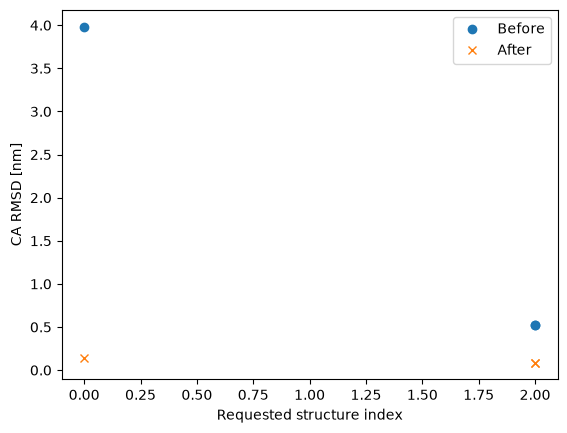

In [4]:
plt.plot(requested, puw.get_value(rmsd_raw, to_unit='nm'), 'o', label='Before')
plt.plot(requested, puw.get_value(rmsd_opt, to_unit='nm'), 'x', label='After')
plt.xlabel('Requested structure index')
plt.ylabel('CA RMSD [nm]')
plt.legend()
plt.show()


(course-alzheimer-comparison-superposition-see-also)=
:::{seealso}
:class: dropdown

- {ref}`Tutorial_Least_rmsd_align`
- {ref}`Cookbook_Aligning_Components_By_Sequence`
- {ref}`course-core-structural-operations`
- {func}`molsysmt.structure.get_rmsd`
:::
